In [1]:
import xarray as xr
import numpy as np
import scipy.sparse as sps
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib as mpl
import glob

In [2]:
import dask
from dask.distributed import wait
dask.__version__

'2024.7.0'

In [3]:
# Close out Dask Cluster and release workers:
#cluster.close()
#client.close()

In [4]:
# TODO: optimize dask resources

def get_ClusterClient():
    import dask
    from dask_jobqueue import PBSCluster
    from dask.distributed import Client
    cluster = PBSCluster(
        cores=1,
        memory='10GB',
        processes=1,
        queue='casper',
        resource_spec='select=1:ncpus=1:mem=10GB',
        project='NCGD0011',
        walltime='04:00:00',
        interface='ext',)

    dask.config.set({
        'distributed.dashboard.link':
        'https://jupyterhub.hpc.ucar.edu/stable/user/{USER}/proxy/{port}/status'
    })
    client = Client(cluster)
    return cluster, client

cluster, client = get_ClusterClient()
cluster.scale(36) 

/glade/u/apps/opt/conda/envs/npl-2024b/lib/python3.11/site-packages/dask_jobqueue/core.py:266: FutureWarning: job_extra has been renamed to job_extra_directives. You are still using it (even if only set to []; please also check config files). If you did not set job_extra_directives yet, job_extra will be respected for now, but it will be removed in a future release. If you already set job_extra_directives, job_extra is ignored and you can remove it.
  warnings.warn(warn, FutureWarning)
/glade/u/apps/opt/conda/envs/npl-2024b/lib/python3.11/site-packages/dask_jobqueue/pbs.py:82: FutureWarning: project has been renamed to account as this kwarg was used wit -A option. You are still using it (please also check config files). If you did not set account yet, project will be respected for now, but it will be removed in a future release. If you already set account, project is ignored and you can remove it.
  warnings.warn(warn, FutureWarning)
/glade/u/apps/opt/conda/envs/npl-2024b/lib/python3.1

In [5]:
cluster

Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/fredc/proxy/46837/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://128.117.208.173:37255,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/fredc/proxy/46837/status,Total threads: 0
Started: Just now,Total memory: 0 B


In [6]:
fdir = '/glade/campaign/collections/rda/data/d651009/'
outdir = '/glade/derecho/scratch/fredc/RDA/'
case = 'b.e13.BRCP85C5.ne120_t12.cesm-ihesp-hires1.0.46-2006-2100.010'

In [7]:
fpath = '{}/{}/atm/proc/tseries/month_1/{}.cam.h0.TREFHT.*.nc'.format(fdir,case,case)
flst = sorted(glob.glob(fpath))

ds = xr.open_mfdataset(flst,
                       parallel=True, # use dask to read in parallel
                       combine="nested",  # combine files in order provided
                       concat_dim="time",  # concatentate files along time dimension
                       data_vars="minimal",  # only concatentate data variables with "time" dimension
                       coords="minimal",  # same as above for coordinate variables
                       compat="override",
                       #preprocess=preprocess, # run this function on each dataset first before combining
                       chunks={ "time":1,}, # choose simple
                       )

In [8]:
ds.TREFHT

<xarray.DataArray 'TREFHT' (time: 1140, ncol: 777602)> Size: 4GB
dask.array<concatenate, shape=(1140, 777602), dtype=float32, chunksize=(1, 777602), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) object 9kB 2006-02-01 00:00:00 ... 2101-01-01 00:00:00
Dimensions without coordinates: ncol
Attributes:
    units:         K
    long_name:     Reference height temperature
    cell_methods:  time: mean

In [9]:
#wgtfile = '/glade/work/fredc/Regrid_Maps/ne120np4_pentagons_to_latlon_0.25x0.25_0E_bilinear_20210903.nc'
wgtfile = '/glade/work/fredc/Regrid_Maps/ne120np4_pentagons_to_latlon_0.25x0.25_0E_conserve_20200309.nc'
dsw = xr.open_dataset(wgtfile)

In [10]:
def remap_camse(ds, dsw, varlst=[]):
    dso = xr.full_like(ds.drop_dims('ncol'), np.nan)
    lonb = dsw.xc_b.values.reshape([dsw.dst_grid_dims[1].values, dsw.dst_grid_dims[0].values])
    latb = dsw.yc_b.values.reshape([dsw.dst_grid_dims[1].values, dsw.dst_grid_dims[0].values])
    weights = sps.coo_matrix((dsw.S, (dsw.row-1, dsw.col-1)), shape=[dsw.sizes['n_b'], dsw.sizes['n_a']])
    if not varlst:
        for varname in list(ds):
            if 'ncol' in(ds[varname].dims):
                varlst.append(varname)
        if 'lon' in varlst: varlst.remove('lon')
        if 'lat' in varlst: varlst.remove('lat')
        if 'area' in varlst: varlst.remove('area')
    for varname in varlst:
        shape = ds[varname].shape
        invar_flat = ds[varname].values.reshape(-1, shape[-1])
        remapped_flat = weights.dot(invar_flat.T).T
        remapped = remapped_flat.reshape([*shape[0:-1], dsw.dst_grid_dims[1].values, dsw.dst_grid_dims[0].values])
        dimlst = list(ds[varname].dims[0:-1])
        dims={}
        coords={}
        for it in dimlst:
            dims[it] = dso.sizes[it]
            coords[it] = dso.coords[it]
        dims['lat'] = int(dsw.dst_grid_dims[1])
        dims['lon'] = int(dsw.dst_grid_dims[0])
        coords['lat'] = latb[:,0]
        coords['lon'] = lonb[0,:]
        remapped = xr.DataArray(remapped, coords=coords, dims=dims, attrs=ds[varname].attrs)
        dso = xr.merge([dso, remapped.to_dataset(name=varname)])
    varlst.clear() #not sure why this is needed but varlst was not cleared and it created issues with successive call to remap_camse
    return dso

In [11]:
%%time
dso = remap_camse(ds,dsw)

/glade/u/apps/opt/conda/envs/npl-2024b/lib/python3.11/site-packages/numpy/core/numeric.py:407: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')


CPU times: user 9.52 s, sys: 4.85 s, total: 14.4 s
Wall time: 33.8 s


In [12]:
dso

<xarray.Dataset> Size: 9GB
Dimensions:        (lev: 30, ilev: 31, cosp_prs: 7, nbnd: 2, cosp_tau: 7,
                    cosp_ht: 40, cosp_sr: 15, time: 1140, cosp_scol: 50,
                    cosp_sza: 5, lat: 720, lon: 1440)
Coordinates:
  * lev            (lev) float64 240B 3.643 7.595 14.36 ... 957.5 976.3 992.6
  * ilev           (ilev) float64 248B 2.255 5.032 10.16 ... 967.5 985.1 1e+03
  * cosp_prs       (cosp_prs) float64 56B 900.0 740.0 620.0 ... 375.0 245.0 90.0
  * cosp_tau       (cosp_tau) float64 56B 0.15 0.8 2.45 6.5 16.2 41.5 219.5
  * cosp_scol      (cosp_scol) int32 200B 1 2 3 4 5 6 7 ... 44 45 46 47 48 49 50
  * cosp_ht        (cosp_ht) float64 320B 240.0 720.0 ... 1.848e+04 1.896e+04
  * cosp_sr        (cosp_sr) float64 120B 0.605 2.1 4.0 ... 70.0 539.5 1.004e+03
  * cosp_sza       (cosp_sza) float64 40B 0.0 15.0 30.0 45.0 60.0
  * time           (time) object 9kB 2006-02-01 00:00:00 ... 2101-01-01 00:00:00
  * lat            (lat) float64 6kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * lon            (lon) float64 12kB 0.125 0.375 0.625 ... 359.4 359.6 359.9
Dimensions without coordinates: nbnd
Data variables: (12/32)
    hyam           (lev) float64 240B dask.array<chunksize=(30,), meta=np.ndarray>
    hybm           (lev) float64 240B dask.array<chunksize=(30,), meta=np.ndarray>
    P0             float64 8B nan
    hyai           (ilev) float64 248B dask.array<chunksize=(31,), meta=np.ndarray>
    hybi           (ilev) float64 248B dask.array<chunksize=(31,), meta=np.ndarray>
    cosp_prs_bnds  (cosp_prs, nbnd) float64 112B dask.array<chunksize=(7, 2), meta=np.ndarray>
    ...             ...
    n2ovmr         (time) float64 9kB dask.array<chunksize=(1,), meta=np.ndarray>
    f11vmr         (time) float64 9kB dask.array<chunksize=(1,), meta=np.ndarray>
    f12vmr         (time) float64 9kB dask.array<chunksize=(1,), meta=np.ndarray>
    sol_tsi        (time) float64 9kB dask.array<chunksize=(1,), meta=np.ndarray>
    nsteph         (time) int32 5kB dask.array<chunksize=(1,), meta=np.ndarray>
    TREFHT         (time, lat, lon) float64 9GB 242.8 242.8 ... 274.5 274.5
Attributes:
    np:               4
    ne:               120
    Conventions:      CF-1.0
    source:           CAM
    case:             b.e13.BRCP85C5.ne120_t12.cesm-ihesp-hires1.0.46-2006-21...
    title:            UNSET
    logname:          fredc
    host:             derecho3
    Version:          $Name$
    revision_Id:      $Id$
    initial_file:     b.e13.BHISTC5.ne120_t12.cesm-ihesp-hires1.0.46-1920-200...
    topography_file:  /glade/campaign/cesm/cesmdata/cseg/inputdata/atm/cam/to...

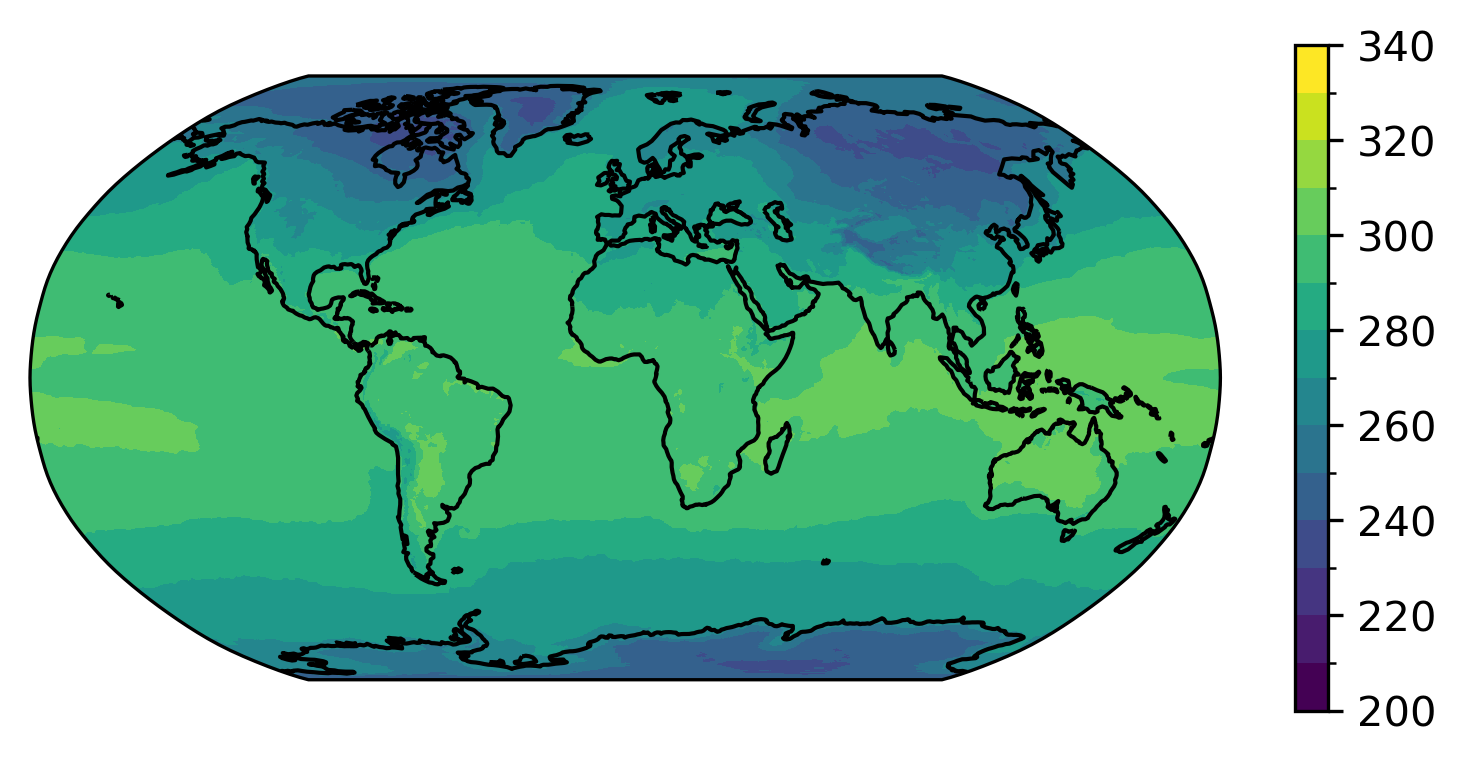

In [13]:
cmap = plt.cm.viridis
clevs = np.arange(0,15,1)*10+200
lon, lat = np.meshgrid(dso.lon.values, dso.lat.values)
plt.figure(dpi=300)
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))
cf = ax.pcolormesh(lon, lat, dso.TREFHT.isel(time=0), 
                   cmap=cmap,
                   norm=mpl.colors.BoundaryNorm(clevs, ncolors=cmap.N), 
                   transform=ccrs.PlateCarree()
                   )
ax.coastlines()
ax.set_global()
plt.colorbar(cf, shrink=0.6)